In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

ruta = "/content/drive/MyDrive/ALTAIR/Altair_measurements_aligned.csv"

altair = pd.read_csv(ruta)

altair.columns = altair.columns.str.strip()

altair.head()

,deviceModel,interval,rsrq_mean,rsrq_std,rsrp_mean,rsrp_std,rssi_mean,rssi_std,lat_mean,lon_mean
0,Brand A model 1,I1 13:21-13:23,-17.583333,1.164500,-98.666667,1.669694,-61.166667,2.622744,-16.406457,-71.524358
1,Brand A model 1,I2 13:24-13:26,-16.416667,1.240112,-95.583333,2.108784,-59.166667,2.622744,-16.406411,-71.524379
2,Brand A model 1,I3 13:27-13:29,-16.250000,1.356801,-98.583333,2.539088,-62.500000,2.576114,-16.406337,-71.524350
3,Brand A model 1,I4 13:30-13:32,-17.600000,1.341641,-103.200000,2.489980,-64.200000,1.788854,-16.406408,-71.524336
4,Brand A model 1,I5 13:33-13:35,-19.416667,1.083625,-105.916667,2.020726,-65.500000,2.110579,-16.406339,-71.524322


In [3]:
import pandas as pd

ruta = "/content/drive/MyDrive/ALTAIR/nemo_measurements_aligned.csv"

nemo = pd.read_csv(ruta, sep=",")

nemo.columns = nemo.columns.str.strip()

nemo.head()

,interval,N°_Samples,rsrq_mean,rsrq_std,rsrp_mean,rsrp_std,rssi_mean,rssi_std,lat_mean,lon_mean
0,I1 13:21-13:23,151,-15.270861,1.343954,-97.094040,2.978372,-62.154305,3.389370,-16.406505,-71.524329
1,I2 13:24-13:26,148,-14.793919,0.697637,-91.499324,0.931132,-56.559459,1.174435,-16.406451,-71.524364
2,I3 13:27-13:29,157,-16.478981,2.154662,-97.615924,1.487017,-62.222293,2.922078,-16.406379,-71.524417
3,I4 13:30-13:32,149,-18.908725,1.750982,-100.626174,1.749880,-61.483221,1.409783,-16.406406,-71.524485
4,I5 13:33-13:35,144,-16.679861,1.201664,-100.268056,2.468647,-64.876389,3.697003,-16.406333,-71.524509


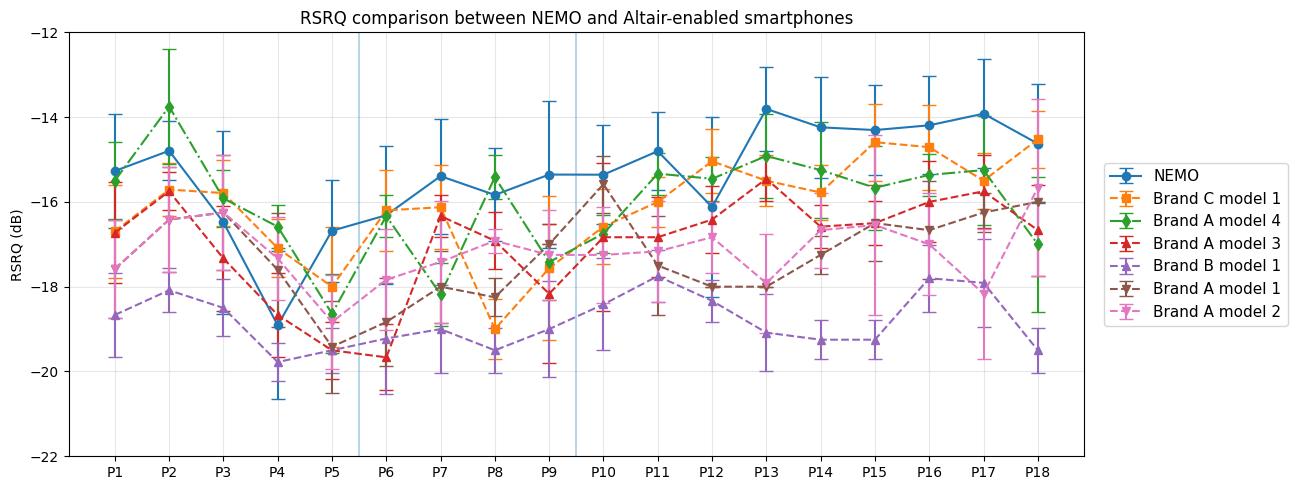

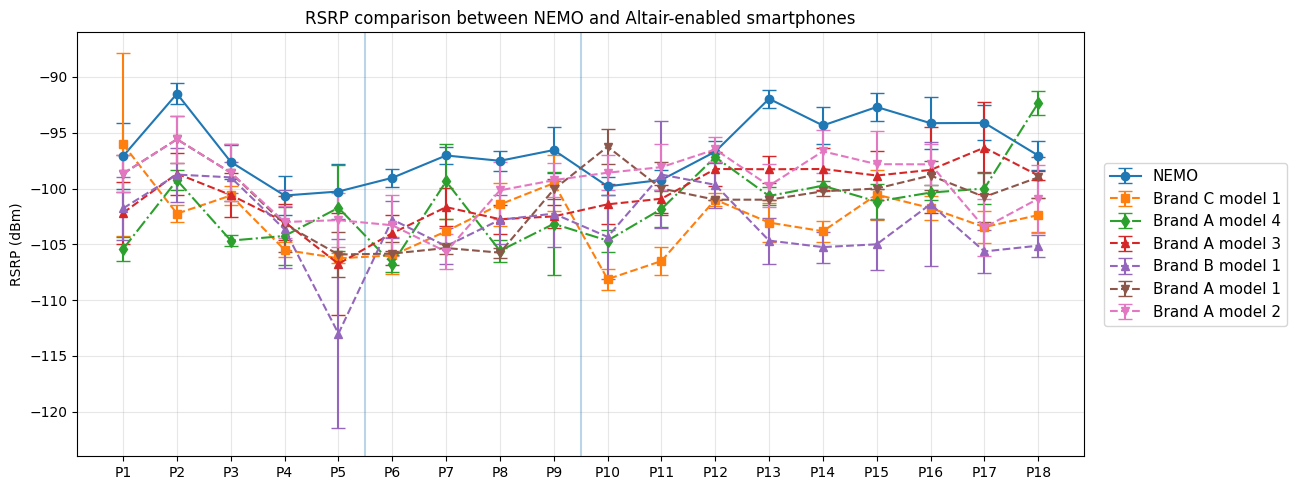

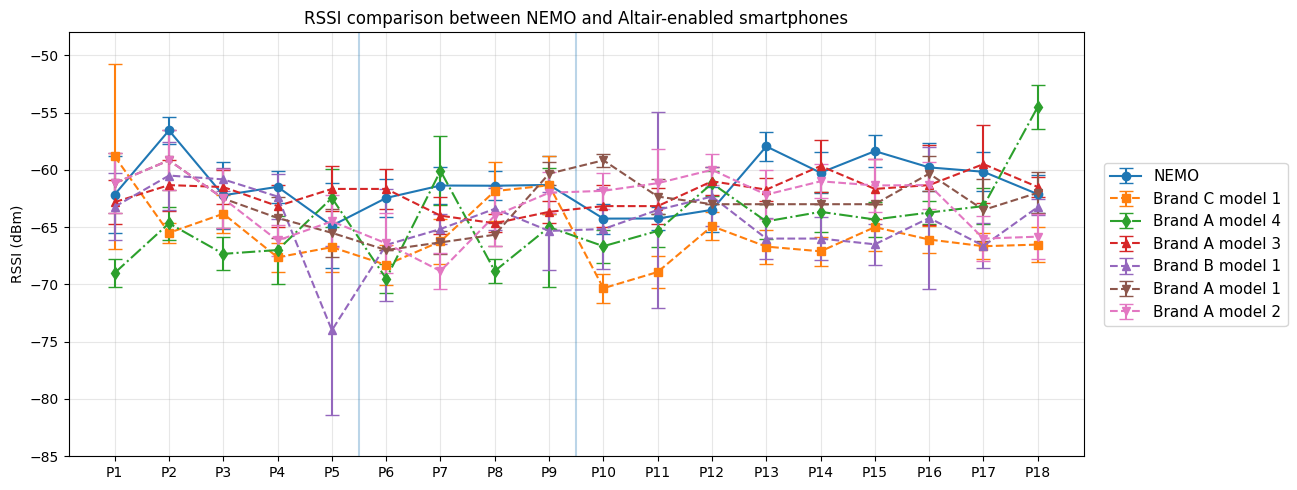

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

if "deviceModel" not in nemo.columns:
    nemo["deviceModel"] = "NEMO"

df_all = pd.concat([nemo, altair], ignore_index=True)

df_all = df_all.dropna(subset=["deviceModel"])

df_all["I"] = df_all["interval"].astype(str).str.extract(r"I(\d+)", expand=False)
df_all = df_all.dropna(subset=["I"])
df_all["I"] = df_all["I"].astype(int)

N = 18
cuts = [5, 9]
x = np.arange(N)
x_labels = [f"P{i+1}" for i in range(N)]

model_styles = {
    "NEMO":            {"fmt": "o-",  "color": "tab:blue"},
    "Brand C model 1": {"fmt": "s--", "color": "tab:orange"},
    "Brand A model 4": {"fmt": "d-.", "color": "tab:green"},
    "Brand A model 3": {"fmt": "^--", "color": "tab:red"},
    "Brand B model 1": {"fmt": "^--", "color": "tab:purple"},
    "Brand A model 1": {"fmt": "v--", "color": "tab:brown"},
    "Brand A model 2": {"fmt": "v--", "color": "tab:pink"}
}

def get_y_limits(mean_col):
    if mean_col == "rsrq_mean": return (-22, -12)
    if mean_col == "rsrp_mean": return (-124, -86)
    if mean_col == "rssi_mean": return (-85, -48)
    return None

def plot_kpi(df, mean_col, std_col, ylabel, title):
    plt.figure(figsize=(16, 5))

    desired_order = [
        "NEMO",
        "Brand C model 1",
        "Brand A model 4",
        "Brand A model 3",
        "Brand B model 1",
        "Brand A model 1",
        "Brand A model 2"
    ]

    plot_order = [m for m in desired_order if m in df["deviceModel"].unique()]

    for model in plot_order:
        df_model = df[df["deviceModel"] == model].copy()

        df_model = df_model.set_index("I").reindex(range(1, N + 1))

        y = df_model[mean_col].values
        e = df_model[std_col].fillna(0).values
        style = model_styles.get(model, {"fmt": ".-"})

        plt.errorbar(x, y, yerr=e, label=model, capsize=5, **style)

    plt.xticks(x, x_labels, rotation=0)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)

    for cut in cuts:
        if cut < N:
            plt.axvline(cut - 0.5, alpha=0.3)

    ylim = get_y_limits(mean_col)
    if ylim is not None:
        plt.ylim(ylim)

    plt.legend(
        fontsize=11,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        borderaxespad=0
    )

    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()

plot_kpi(df_all, "rsrq_mean", "rsrq_std", "RSRQ (dB)",
         "RSRQ comparison between NEMO and Altair-enabled smartphones")

plot_kpi(df_all, "rsrp_mean", "rsrp_std", "RSRP (dBm)",
         "RSRP comparison between NEMO and Altair-enabled smartphones")

plot_kpi(df_all, "rssi_mean", "rssi_std", "RSSI (dBm)",
         "RSSI comparison between NEMO and Altair-enabled smartphones")

In [5]:
import pandas as pd
import numpy as np

cellular_models = [m for m in df_all["deviceModel"].unique()
                   if pd.notna(m) and str(m).lower() != "nan" and m != "NEMO"]

kpis_to_evaluate = [
    ("RSRQ (dB)", "rsrq_mean"),
    ("RSRP (dBm)", "rsrp_mean"),
    ("RSSI (dBm)", "rssi_mean")
]

results = []

for kpi_name, column in kpis_to_evaluate:

    df_pivot = df_all.pivot_table(index='I', columns='deviceModel', values=column, aggfunc='mean')

    # Individual device comparison
    for model in cellular_models:
        if model in df_pivot.columns and "NEMO" in df_pivot.columns:
            comp = df_pivot[["NEMO", model]].dropna()
            if not comp.empty:
                y_ref = comp["NEMO"]
                y_pred = comp[model]

                error = y_pred - y_ref
                bias = np.mean(error)
                mae = np.mean(np.abs(error))
                rmse = np.sqrt(np.mean(error**2))
                correlation = y_pred.corr(y_ref)

                results.append({
                    "KPI": kpi_name,
                    "Device": model,
                    "Bias": round(bias, 3),
                    "MAE": round(mae, 3),
                    "RMSE": round(rmse, 3),
                    "Correlation": round(correlation, 3)
                })

    # Aggregated average comparison
    df_pivot['Smartphones_Average'] = df_pivot[cellular_models].mean(axis=1)
    comp_avg = df_pivot[["NEMO", 'Smartphones_Average']].dropna()

    if not comp_avg.empty:
        y_ref = comp_avg["NEMO"]
        y_pred = comp_avg['Smartphones_Average']

        error = y_pred - y_ref
        bias = np.mean(error)
        mae = np.mean(np.abs(error))
        rmse = np.sqrt(np.mean(error**2))
        correlation = y_pred.corr(y_ref)

        results.append({
            "KPI": kpi_name,
            "Device": "AVERAGE (All)",
            "Bias": round(bias, 2),
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "Correlation": round(correlation, 3)
        })

In [6]:
df_metrics = pd.DataFrame(results)

df_metrics = df_metrics[df_metrics['Device'] != 'AVERAGE (All)'].copy()

df_metrics['KPI'] = df_metrics['KPI'].replace({
    'RSRP (dBm)': 'RSRP',
    'RSRQ (dB)': 'RSRQ',
    'RSSI (dBm)': 'RSSI'
})

df_metrics = df_metrics.rename(columns={
    "Correlation": "r"
})

kpi_order = {"RSRP": 1, "RSRQ": 2, "RSSI": 3}
df_metrics["order"] = df_metrics["KPI"].map(kpi_order)
df_metrics = df_metrics.sort_values(by=["Device", "order"]).drop(columns=["order"])

df_pub = df_metrics.set_index(['Device', 'KPI'])

df_pub = df_pub.astype(float).round(3)

display(df_pub)

Bias    MAE   RMSE      r
Device          KPI                             
Brand A model 1 RSRP -4.375  4.770  5.403  0.408
                RSRQ -1.928  2.099  2.294  0.388
                RSSI -1.484  2.550  3.126  0.226
Brand A model 2 RSRP -3.301  3.585  4.416  0.427
                RSRQ -1.814  2.014  2.246  0.146
                RSSI -1.720  2.871  3.445  0.219
Brand A model 3 RSRP -4.126  4.126  4.527  0.755
                RSRQ -1.650  1.677  1.873  0.729
                RSSI -0.707  1.959  2.333  0.279
Brand A model 4 RSRP -5.048  5.571  6.106  0.394
                RSRQ -0.684  1.242  1.462  0.419
                RSSI -3.137  4.652  5.166  0.015
Brand B model 1 RSRP -6.763  6.816  7.819  0.169
                RSRQ -3.452  3.452  3.624  0.435
                RSSI -3.358  3.724  4.613  0.254
Brand C model 1 RSRP -6.379  6.496  7.044  0.431
                RSRQ -0.778  1.200  1.415  0.511
                RSSI -4.337  4.707  5.388  0.166

In [7]:

df_average = pd.DataFrame(results)

df_average = df_average[df_average['Device'] == 'AVERAGE (All)'].copy()

df_average['KPI'] = df_average['KPI'].replace({
    'RSRP (dBm)': 'RSRP',
    'RSRQ (dB)': 'RSRQ',
    'RSSI (dBm)': 'RSSI'
})

df_average = df_average.rename(columns={
    "Correlation": "r"
})

kpi_order = {"RSRP": 1, "RSRQ": 2, "RSSI": 3}
df_average["order"] = df_average["KPI"].map(kpi_order)
df_average = df_average.sort_values(by=["order"]).drop(columns=["order", "Device"])

df_average = df_average.set_index('KPI')
df_average = df_average.astype(float).round(4)

display(df_average)

,Bias,MAE,RMSE,r
KPI,,,,
RSRP,-5.00,5.00,5.44,0.628
RSRQ,-1.72,1.84,1.96,0.629
RSSI,-2.46,2.63,3.24,0.348
